# Exercises XP: Introduction to LLMs

Use this guided notebook to follow the platform instructions step by step. Prefilled cells are ready to run; cells containing **TODO** markers need your input.


## 👩‍🏫👩🏿‍🏫 What you’ll learn
- Understand what Large Language Models (LLMs) can do.
- Review the Transformer architecture and the tokenization pipeline.
- Differentiate between pretraining and fine-tuning.
- Generate text with a pretrained language model.


## 🛠️ What you will create
- Markdown answers describing key NLP concepts.
- Python code that loads GPT-2 (or a similar causal LM) and performs basic tokenization and generation.


> **Learning point**
> Work through the exercises sequentially. Run installation cells only once, then focus on filling each TODO before executing the corresponding code.


## 🌟 Exercise 1 · What are Large Language Models?


### 1.1 Define LLMs

Large Language Models (LLMs) are artificial intelligence systems trained on massive datasets of text and code to understand, generate, and interact with human language. At their core, they use complex neural networks—typically based on an architecture called a transformer—to recognize patterns in data. Instead of being explicitly programmed with grammar rules, they learn to predict the most logical next word in a sequence based on the context of the words that came before it.

Because they have internalized the structure of language and vast amounts of factual information, LLMs are highly versatile and designed to tackle a wide variety of tasks:

Text Generation: Writing everything from professional emails and marketing copy to creative stories, poetry, and structured reports.

Code Generation & Debugging: Writing functional code in various programming languages, explaining complex codebases, and identifying syntax errors or bugs.

Summarization: Condensing lengthy documents, meeting transcripts, or articles into concise, actionable bullet points without losing the core meaning.

Information Extraction: Pulling specific data points—like names, dates, or financial figures—out of large, unstructured text files.

Translation: Fluently translating text not only between human languages but also between programming languages.

Conversational Assistance: Powering chatbots and virtual assistants that can answer questions, provide customer support, and engage in logical, multi-turn dialogue.

Classification & Analysis: Categorizing text, such as determining if a customer review is positive or negative (sentiment analysis) or routing support tickets by topic.


### 1.2 Prefilled · install core libraries
Run once to install `transformers`, `torch`, and supporting utilities exactly as in the enoncé.


In [1]:
%pip install --quiet transformers matplotlib --upgrade


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 54.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 46.1 MB/s eta 0:00:00


### 1.3 Load GPT for causal text generation
Reuse the snippet from the platform: declare the model name, tokenizer, and model weights.


In [2]:
from transformers import AutoTokenizer, AutoModelForCausalLM, pipeline
import torch
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

model_name = "gpt2" # GPT-2 is used here for demonstration; can be replaced with models like "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(model_name)

if None in (model_name, tokenizer, model):
    raise ValueError("Fill in model_name, tokenizer, and model before continuing.")

print(f"\nModel '{model_name}' loaded successfully!")
print("""
GPT-2 is a causal language model, meaning it predicts the next word in a sequence.
It has been trained on a diverse dataset and can generate coherent, contextually relevant text.
""")


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]


Model 'gpt2' loaded successfully!

GPT-2 is a causal language model, meaning it predicts the next word in a sequence.
It has been trained on a diverse dataset and can generate coherent, contextually relevant text.



## 🌟 Exercise 2 · Transformer Architecture and Tokenization


The Tokenization Process: Tokenization is the process of translating human-readable text into a sequence of numbers (token IDs) that a neural network can process. Since LLMs cannot do math on raw text, tokenization acts as the critical bridge between human language and machine logic.

Most modern LLMs (including GPT-2) use subword tokenization. The standard pipeline follows these steps:

Normalization: The raw text undergoes basic cleanup. Depending on the model, this might involve converting characters to lowercase, stripping accents, or standardizing white space. (Note: Many modern models, like GPT-2, skip aggressive normalization to preserve the exact original formatting and casing).

Pre-tokenization: The text is roughly split into foundational units, typically by dividing it at spaces and punctuation marks to create raw word boundaries.

Subword Splitting: The tokenizer compares these chunks against its predefined vocabulary dictionary to break them into recognized "subwords." Common words remain intact (e.g., "apple" $\rightarrow$ ["apple"]). Rare, complex, or misspelled words are broken into smaller, known fragments (e.g., "unbelievably" $\rightarrow$ ["un", "believ", "ably"]). This prevents the model from crashing when it encounters a word it has never seen before.

ID Mapping: Each text fragment is replaced by its corresponding integer ID from the tokenizer's vocabulary dictionary.

Adding Special Tokens: The tokenizer appends model-specific control tokens that give the LLM structural cues. This can include end-of-sequence tokens (like GPT-2's <|endoftext|>), classification tokens, or padding tokens used to make a batch of inputs uniform in length.Here is a conceptual look at how a sentence transforms:

PlaintextInput Text: "Tokenization is fascinating!"
Tokens:     ["Token", "ization", " is", " fascinating", "!"]
Token IDs:  [11241, 1634, 318, 18566, 0]

---




Original Text: The dwarven cleric rolled a natural twenty.
Tokens: ['The', 'Ġdwar', 'ven', 'Ġcleric', 'Ġrolled', 'Ġa', 'Ġnatural', 'Ġtwenty', '.']
Token IDs: [464, 15594, 574, 33824, 11686, 257, 3288, 8208, 13]


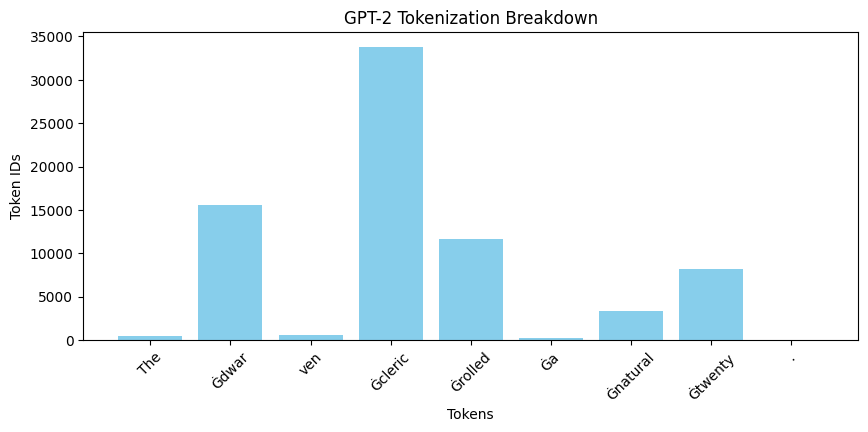

In [3]:
import matplotlib.pyplot as plt

text = "The dwarven cleric rolled a natural twenty."

if text is None:
    raise ValueError("Define the variable `text` with a short sentence.")

tokens = tokenizer.tokenize(text)
token_ids = tokenizer.convert_tokens_to_ids(tokens)

print(f"Original Text: {text}")
print(f"Tokens: {tokens}")
print(f"Token IDs: {token_ids}")

x_label = "Tokens"
y_label = "Token IDs"
title = "GPT-2 Tokenization Breakdown"

if None in (x_label, y_label, title):
    raise ValueError("Set x_label, y_label, and title before plotting.")

plt.figure(figsize=(10, 4))
plt.bar(tokens, token_ids, color="skyblue")
plt.xlabel(x_label)
plt.ylabel(y_label)
plt.title(title)
plt.xticks(rotation=45)
plt.show()

## 🌟 Exercise 3 · Token IDs and special prefixes


In [ ]:
if 'tokens' not in globals() or 'token_ids' not in globals():
    raise ValueError("Run Exercise 2 to define `tokens` and `token_ids` first.")

# Iterate over `tokens` and `token_ids`, printing each mapping
print("Token to ID Mapping:")
print("-" * 20)
for token, token_id in zip(tokens, token_ids):
    print(f"Token: {token!r:<15} -> ID: {token_id}")

The Ġ symbol is simply the tokenizer's way of representing a blank space.

Because standard, invisible whitespace can easily get lost, trimmed, or misinterpreted during basic data processing, GPT-style tokenizers (which use Byte-Pair Encoding) convert spaces into this visible character before breaking the text into subwords.

This ensures the model can always distinguish between a word at the beginning of a sentence and a word that follows a space. To the tokenizer, apple (no space before it) and Ġapple (with a space before it) are two entirely different tokens with different numerical IDs, helping the model understand exact word boundaries and formatting.


## 🌟 Exercise 4 · Generate simple text


Create a fresh prompt, run the generator, and observe how the model extends your sentence token by token.


In [4]:
generator = pipeline(
    "text-generation",
    model=model,
    tokenizer=tokenizer,
    device=0 if torch.cuda.is_available() else -1,
)

input_text = "The dwarven cleric raised his warhammer, calling upon Helm to smite his enemies."

if input_text is None:
    raise ValueError("Set `input_text` before generating.")

gen_kwargs = {
    "max_new_tokens": 50,
    "temperature": 0.8,
    "top_p": 0.95,
    "do_sample": True,
}

output_ids = generator(input_text, **gen_kwargs)
output_text = output_ids[0]["generated_text"]

print(f"Input: {input_text}")
print(f"\nGenerated Output:\n{output_text}")

[transformers] Passing `generation_config` together with generation-related arguments=({'top_p', 'do_sample', 'max_new_tokens', 'temperature'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=50) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


Input: The dwarven cleric raised his warhammer, calling upon Helm to smite his enemies.

Generated Output:
The dwarven cleric raised his warhammer, calling upon Helm to smite his enemies.

He fired his gun twice, hitting the goblin that was lying in wait for him, a large-scale brawl breaking out in the hall. He took aim at Helm's bow, striking the orc as he was lying in wait.




> **Learning point**
Temperature is the knob that fundamentally changes the writing style and creativity, whereas max_new_tokens strictly controls length without altering the nature of the prose.

Here is how each parameter impacts the output:

Temperature (Style & Randomness Driver):

Low (0.1 – 0.3): Makes the output rigid, conservative, and highly repetitive. The model picks only the highest-probability words, leading to predictable and safe text.

Moderate (0.7 – 0.8): Balances logical context with diverse word choices, yielding natural, human-like, creative continuation.

High (1.2 – 1.5+): Flattens the probability distribution, giving rare words a much higher chance of selection. This creates surreal, chaotic, or ungrammatical text.

Max New Tokens (Length & Stopping Criteria):

Determines how far the generator continues before cutting off.

It has zero effect on vocabulary choice or tone—setting it to 20 versus 200 simply determines whether you get a short snippet or several paragraphs of the exact same underlying style.

Top_p / Nucleus Sampling (Safety Guardrail):

Works alongside temperature by dynamically trimming the "long tail" of extremely improbable words (e.g., keeping only the top options that make up 95% of cumulative probability) before temperature samples from them.


Here's a summary that can help you decide of how to fix these parameters:

![image.png](https://github.com/user-attachments/assets/a4c444d7-fab8-4f56-b7c7-00a15900cb5a)